# 04_Geographic_Analysis — Spatial Patterns & Regional Comparison

In [1]:
import os
if 'notebooks' in os.getcwd():
    os.chdir('..')
print(f'Working directory: {os.getcwd()}')

Working directory: D:\Data analyst\Portfolio\project-1-refugee-integration


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
sns.set_style('whitegrid')
print('✓ Libraries loaded')

✓ Libraries loaded


In [3]:
master = pd.read_parquet('data/processed/refugee_master_consolidated.parquet')
print(f'Data shape: {master.shape}')
print(f'Unique countries: {master["Country of asylum"].nunique()}')

Data shape: (29506, 27)
Unique countries: 42


## 1. Regional Statistics

In [4]:
# Latest year only
latest = master[master['Year'] == master['Year'].max()]

regional = latest.groupby('region_un').agg({
    'integration_index': ['mean', 'std', 'min', 'max'],
    'Country of asylum': 'nunique',
    'Refugees under UNHCR\'s mandate': 'sum'
}).round(2)

regional.columns = ['Mean Index', 'Std Dev', 'Min', 'Max', 'Countries', 'Total Refugees']
regional = regional.sort_values('Mean Index', ascending=False)
print(regional)

           Mean Index  Std Dev    Min    Max  Countries  Total Refugees
region_un                                                              
Oceania         69.23     0.00  69.23  69.23          1           54430
Americas        63.86     5.12  49.07  73.28         10          368986
Asia            63.63     5.68  48.73  71.16          9         1090669
Africa          60.15     8.20  49.68  78.04         11         1536009
Europe          58.10     5.81  48.15  68.20         10         1034530


## 2. Continental Breakdown

In [5]:
continental = latest.groupby('continent').agg({
    'integration_index': ['mean', 'std'],
    'Country of asylum': 'nunique',
    'Asylum-seekers': 'sum'
}).round(2)

continental.columns = ['Mean Index', 'Std Dev', 'Countries', 'Total Asylum-Seekers']
continental = continental.sort_values('Mean Index', ascending=False)
print(continental)

               Mean Index  Std Dev  Countries  Total Asylum-Seekers
continent                                                          
Oceania             69.23     0.00          1                 90549
South America       66.36     5.74          5                137548
Asia                63.63     5.68          9                 37574
North America       61.34     2.60          5                366590
Africa              60.15     8.20         11                138895
Europe              58.10     5.81         10                 88951


## 3. Regional Boxplot

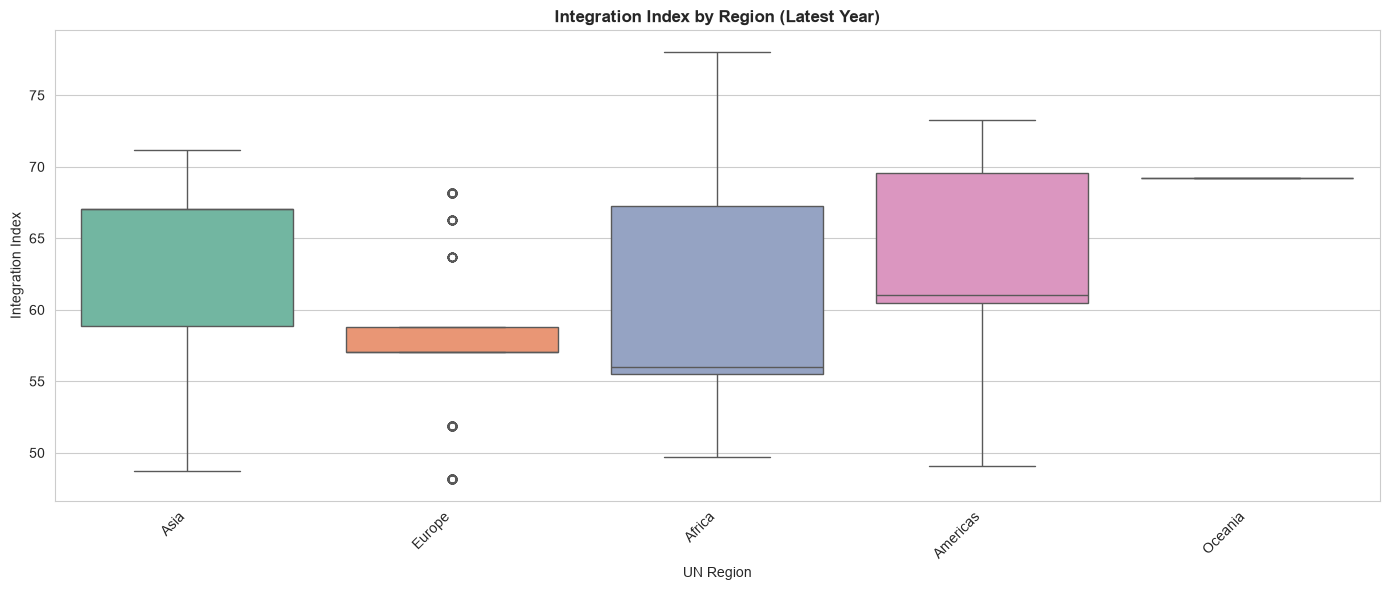

✓ Saved: 04_regional_boxplot.png


In [7]:
fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=latest, x='region_un', y='integration_index', hue='region_un', palette='Set2', ax=ax, legend=False)
ax.set_title('Integration Index by Region (Latest Year)', fontsize=12, fontweight='bold')
ax.set_xlabel('UN Region')
ax.set_ylabel('Integration Index')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('output/04_regional_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 04_regional_boxplot.png')

## 4. Top & Bottom Countries

In [8]:
country_avg = latest.groupby('Country of asylum')['integration_index'].mean().sort_values()

print('\n=== TOP 10 COUNTRIES ===')
for country, index in country_avg.tail(10).items():
    print(f'  {country}: {index:.2f}')

print('\n=== BOTTOM 10 COUNTRIES ===')
for country, index in country_avg.head(10).items():
    print(f'  {country}: {index:.2f}')


=== TOP 10 COUNTRIES ===
  Azerbaijan: 67.18
  Cameroon: 67.24
  Czechia: 68.20
  Australia: 69.23
  Cuba: 69.58
  Brazil: 70.55
  Cambodia: 71.16
  Congo: 71.31
  Belize: 73.28
  Central African Rep.: 78.04

=== BOTTOM 10 COUNTRIES ===
  Bulgaria: 48.15
  Armenia: 48.73
  Bolivia (Plurinational State of): 49.07
  Algeria: 49.68
  Botswana: 50.35
  Burundi: 51.85
  Croatia: 51.91
  Benin: 55.48
  Cote d'Ivoire: 55.97
  Belgium: 57.03


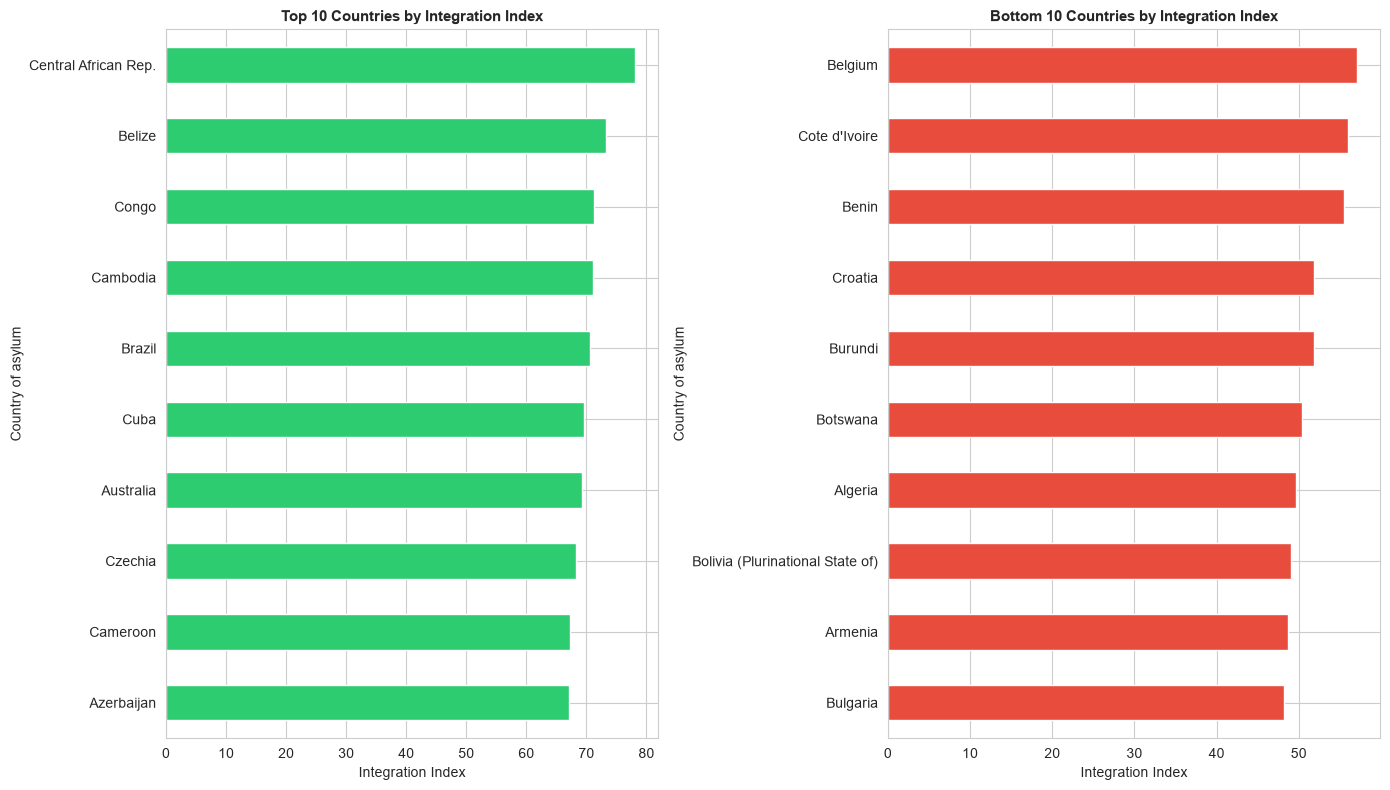

✓ Saved: 04_country_rankings.png


In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 8))

country_avg.tail(10).plot(kind='barh', color='#2ecc71', ax=ax1)
ax1.set_title('Top 10 Countries by Integration Index', fontsize=11, fontweight='bold')
ax1.set_xlabel('Integration Index')

country_avg.head(10).plot(kind='barh', color='#e74c3c', ax=ax2)
ax2.set_title('Bottom 10 Countries by Integration Index', fontsize=11, fontweight='bold')
ax2.set_xlabel('Integration Index')

plt.tight_layout()
plt.savefig('output/04_country_rankings.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 04_country_rankings.png')

## 5. Refugee Load vs Integration Index

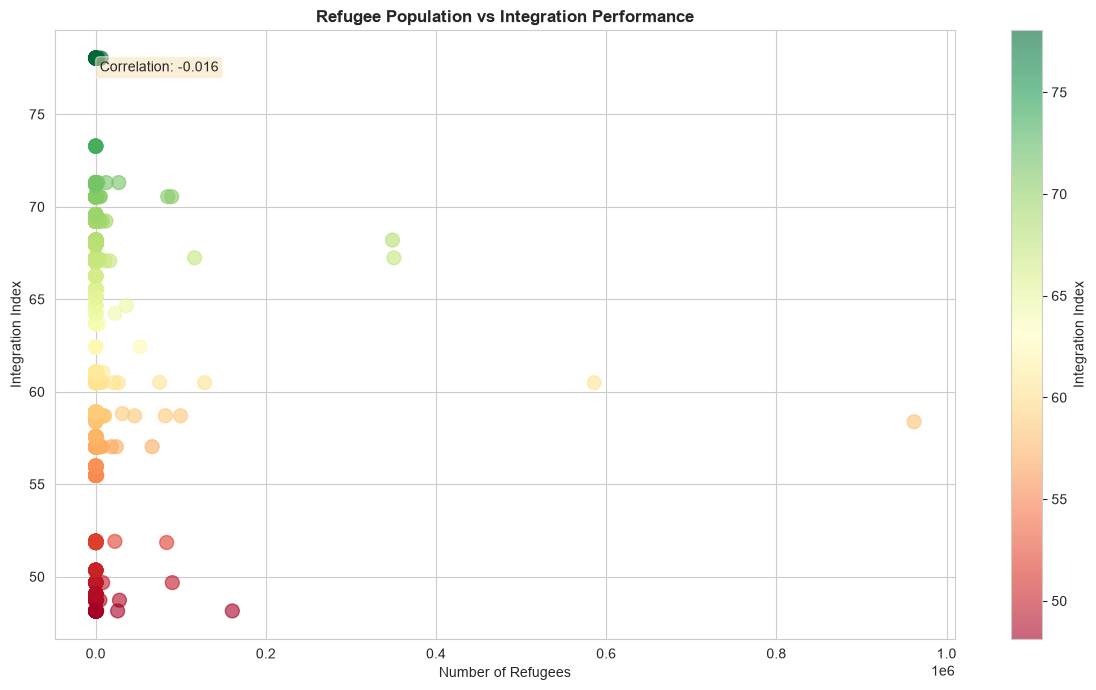

✓ Saved: 04_refugee_load_vs_index.png


In [10]:
fig, ax = plt.subplots(figsize=(12, 7))
scatter = ax.scatter(
    latest['Refugees under UNHCR\'s mandate'],
    latest['integration_index'],
    s=100,
    alpha=0.6,
    c=latest['integration_index'],
    cmap='RdYlGn'
)
ax.set_xlabel('Number of Refugees')
ax.set_ylabel('Integration Index')
ax.set_title('Refugee Population vs Integration Performance', fontsize=12, fontweight='bold')
plt.colorbar(scatter, label='Integration Index')

# Add correlation
corr = latest['Refugees under UNHCR\'s mandate'].corr(latest['integration_index'])
ax.text(0.05, 0.95, f'Correlation: {corr:.3f}', transform=ax.transAxes,
        verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig('output/04_refugee_load_vs_index.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 04_refugee_load_vs_index.png')